# ThemeSync — Results Analysis

Consultation-ready summary of the real, measured results collected so far
against the manuscript's own 4-phase Research Procedure (Chapter 3, pp. 50-58).
Numbers are loaded from actual artifacts in the repo, so re-running this
notebook after a new pipeline run or YOLO retrain refreshes it. **One
exception:** the per-class v2/v3 table is copied from the training console
logs, because Ultralytics doesn't write per-class metrics to `results.csv`.
The v3/v4 per-class numbers come from `results/yolo_v4_experiment.json`
(validation runs).

**Sources used:**
- `runs/yolo/themesync_layout_yolo/results.csv`: Stage 0b YOLOv8, CGL-Dataset pretrain (`themesync_yolo_v1.pt`)
- `runs/yolo/themesync_master_layout_finetune/results.csv`: 65-image real-poster fine-tune (`themesync_yolo_v2.pt`)
- `runs/yolo/themesync_master_layout_finetune_v3/results.csv`: 124-image real-poster fine-tune, continued from v2 (`themesync_yolo_v3.pt`)
- `results/yolo_domain_gap_check.json`: v1/v2/v3 on 3 unseen real posters (`src/evaluation/yolo_domain_gap_check.py`)
- `results/yolo_v4_experiment.json`: v3 vs. v4 (YOLOv8s, 1024 px, cleaned labels) on the same validation labels
- `results/yolo_v5_comparison.json`: v4 vs. the deployed v5 (the group's 200-image re-annotation) on validation images neither trained on (`src/evaluation/yolo_compare.py`)
- `results/gnn_heldout_eval.json`: GNN v1 / v2 / v3 on 2,900 held-out CGL layouts, plus the exact-anchor test (`src/evaluation/gnn_heldout_eval.py`)
- `results/experiment_log.json`: Phase 3 battery, 15 real master layouts × 2 formats × 3 Stage 2 conditions (`src/evaluation/experiment_runner.py`)
- `results/evaluation_results.json`: synthetic certificate comparison plus simulated designer edits (`src/evaluation/evaluate.py`)
- Phase 4 (MOS / expert validation): **no real data yet**; placeholder at the bottom

Full narrative/evidence behind every number: `notes/gnn_fixes_and_methodology_notes.md`
(§3.6-3.7, §3.12, §3.25 and §3.30 for YOLO; §3.22 and §3.26 for the GNN; §3.23, §3.27 and §3.29 for the current Phase 3 setup).

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent  # allow running from notebooks/ or repo root

# Validated categorical palette (dataviz skill reference palette -- fixed order,
# never cycled; slots 1/2 clear the adjacent-pair CVD/contrast gates together).
SERIES_1 = "#2a78d6"   # blue   -- v1 / GNN-guided / "before"
SERIES_2 = "#eb6834"   # orange -- v2 / Baseline / "after"
SERIES_3 = "#1baf7a"   # aqua   -- third series when needed
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e3e2dd"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": TEXT_PRIMARY,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "font.size": 10,
})


# Every figure is also written to results/figures/ for the manuscript: a PNG at
# 300 dpi and a vector PDF, both on a white page. Notebook views are "nb_*";
# the clean Chapter 4 figures at the end are "fig4_*".
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})


def save(fig, name):
    for ext, kw in (("png", {"dpi": 300}), ("pdf", {})):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight", facecolor="white", **kw)


## Phase 1 -- YOLOv8 Layout Parser: CGL Pretrain -> v2 (65 img) -> v3 (124 img) -> v4 -> v5 (deployed)

`themesync_yolo_v1.pt` was trained on the public CGL-Dataset. `themesync_yolo_v2.pt`
fine-tuned it on 65 real, hand-annotated CSPC SSC poster images. `themesync_yolo_v3.pt`
continues from v2 on an expanded 124-image batch (the original 65 plus 59 more).
v1's validation set (CGL's own held-out split) isn't comparable to v2/v3's (this
project's own real-poster held-out split), so v1 gets its own chart; v2 and v3
share a held-out methodology and are directly comparable, so they're overlaid.


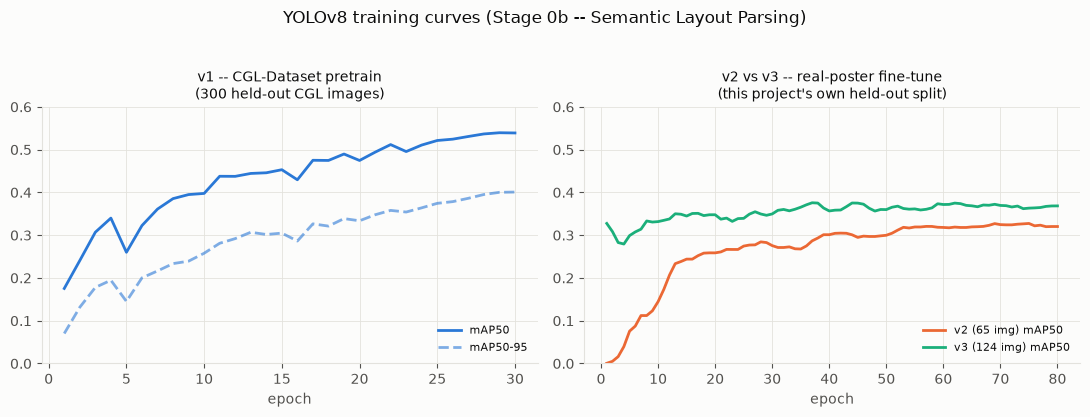

In [2]:
v1 = pd.read_csv(ROOT / "runs/yolo/themesync_layout_yolo/results.csv")
v2 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune/results.csv")
v3 = pd.read_csv(ROOT / "runs/yolo/themesync_master_layout_finetune_v3/results.csv")
v1.columns = [c.strip() for c in v1.columns]
v2.columns = [c.strip() for c in v2.columns]
v3.columns = [c.strip() for c in v3.columns]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(v1["epoch"], v1["metrics/mAP50(B)"], color=SERIES_1, linewidth=2, label="mAP50")
axes[0].plot(v1["epoch"], v1["metrics/mAP50-95(B)"], color=SERIES_1, linewidth=2,
             linestyle="--", alpha=0.6, label="mAP50-95")
axes[0].set_title("v1 -- CGL-Dataset pretrain\n(300 held-out CGL images)", fontsize=10)

for df, label, color in [(v2, "v2 (65 img)", SERIES_2), (v3, "v3 (124 img)", SERIES_3)]:
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=color, linewidth=2, label=f"{label} mAP50")
axes[1].set_title("v2 vs v3 -- real-poster fine-tune\n(this project's own held-out split)", fontsize=10)

for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylim(0, 0.6)
    ax.legend(frameon=False, fontsize=8, loc="lower right")

fig.suptitle("YOLOv8 training curves (Stage 0b -- Semantic Layout Parsing)", y=1.03)
fig.tight_layout()
save(plt.gcf(), "nb_yolo_training_curves")
plt.show()


In [3]:
summary = pd.DataFrame([
    {
        "model": "v1 (CGL pretrain)",
        "val_set": "300 CGL held-out images / 1448 instances",
        "precision": v1["metrics/precision(B)"].iloc[-1],
        "recall": v1["metrics/recall(B)"].iloc[-1],
        "mAP50": v1["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v1["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v2 (65-image real-poster fine-tune)",
        "val_set": "15 held-out real posters",
        "precision": v2["metrics/precision(B)"].iloc[-1],
        "recall": v2["metrics/recall(B)"].iloc[-1],
        "mAP50": v2["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v2["metrics/mAP50-95(B)"].iloc[-1],
    },
    {
        "model": "v3 (124-image real-poster fine-tune)",
        "val_set": "25 held-out real posters",
        "precision": v3["metrics/precision(B)"].iloc[-1],
        "recall": v3["metrics/recall(B)"].iloc[-1],
        "mAP50": v3["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95": v3["metrics/mAP50-95(B)"].iloc[-1],
    },
]).set_index("model")
summary.round(3)


,val_set,precision,recall,mAP50,mAP50-95
model,,,,,
v1 (CGL pretrain),300 CGL held-out images / 1448 instances,0.580,0.478,0.539,0.401
v2 (65-image real-poster fine-tune),15 held-out real posters,0.627,0.304,0.320,0.183
v3 (124-image real-poster fine-tune),25 held-out real posters,0.459,0.349,0.368,0.212


### A real data-quality catch, before v3 existed

Checking the newly-uploaded 124-image export before training on it found two
real problems, confirmed with an actual test run rather than assumed: (1)
~23% of the images were being silently dropped during training because their
label files mixed plain bounding-box rows with polygon rows -- Ultralytics
discards the whole file rather than partially using it; (2) the class index
order had shifted between exports (alphabetized in the new one), which would
have silently scrambled what v2's checkpoint had already learned if fine-tuned
on as-is. Both fixed (polygons converted to their enclosing boxes, indices
remapped) and re-verified (0 corrupt files) before the retrain below ran. Full
detail: `notes/gnn_fixes_and_methodology_notes.md` Section 3.12.


### Per-class breakdown: v2 vs v3

Not in `results.csv` (Ultralytics only logs aggregate metrics there) -- pulled
from the console output captured in `notes/gnn_fixes_and_methodology_notes.md`
Sections 3.7 (v2) and 3.12 (v3). **`underlay` is still weak** (44 validation
instances now, up from 17 -- better, not yet enough to learn well);
**`embellishment` stayed flat** despite the batch nearly doubling (consistent
with the group's decision not to prioritize hunting for these); `logo` and
`text` -- the two structurally important classes -- both improved meaningfully.


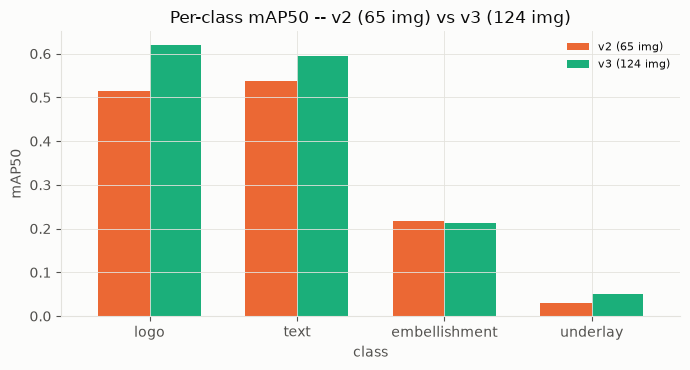

,v2_mAP50,v3_mAP50
class,,
logo,0.5150,0.6200
text,0.5380,0.5950
embellishment,0.2180,0.2130
underlay,0.0288,0.0499


In [4]:
per_class = pd.DataFrame([
    {"class": "logo",          "v2_mAP50": 0.515,  "v3_mAP50": 0.620},
    {"class": "text",          "v2_mAP50": 0.538,  "v3_mAP50": 0.595},
    {"class": "embellishment", "v2_mAP50": 0.218,  "v3_mAP50": 0.213},
    {"class": "underlay",      "v2_mAP50": 0.0288, "v3_mAP50": 0.0499},
]).set_index("class")

ax = per_class.plot(kind="bar", color=[SERIES_2, SERIES_3], figsize=(7, 3.8), width=0.7)
ax.set_ylabel("mAP50")
ax.set_title("Per-class mAP50 -- v2 (65 img) vs v3 (124 img)")
ax.set_xticklabels(per_class.index, rotation=0)
ax.legend(["v2 (65 img)", "v3 (124 img)"], frameon=False, fontsize=8)
plt.tight_layout()
save(plt.gcf(), "nb_yolo_v2_v3_per_class")
plt.show()

per_class


### Real-domain generalization check (v1 -> v2 -> v3, same 3 posters)

Top detection confidence, and the number of detections usable at conf >= 0.25,
on 3 CSPC posters outside the original 65-image annotation batch: a test of
whether fine-tuning closed the CGL-to-real-poster domain gap rather than
memorizing training examples. (`YOUR_TEMPLATE2.jpg`, YUGTO 2026, is left out on
purpose: it was in every fine-tune's training data.)

**Caveat, found 2026-09-28:** TAN-AW was later added to the 124-image batch, so
it *is* in v3's training data (detected automatically by image hash; it was
renamed by Roboflow). Its v3 bars are hatched below and don't count as
generalization. The clean v3 evidence is La Serata and LODT, which no model
has trained on.

Re-measured 2026-09-28 with `src/evaluation/yolo_domain_gap_check.py`. The v2
values match the earlier measurement (0.74 / 0.73 / 0.69). The v1 values replace
hand-typed ones (0.20 / 0.46 / 0.31) that previously sat in this cell and didn't
match any saved measurement; the re-measured v1 La Serata value (0.035) matches
the original v1 log in notes §3.5.

**How to read v2 vs v3 here:** v3 is more confident on all three posters, but
finds fewer usable detections on two of them (La Serata 16 -> 10, TAN-AW 13 ->
9; LODT 8 -> 11). These posters have no hand-drawn ground truth, so this check
can't tell whether the drop means fewer false positives or more misses. It
shows the domain gap *stays closed*; accuracy comes from the held-out mAP table
above (v3 0.370 vs v2 0.320).

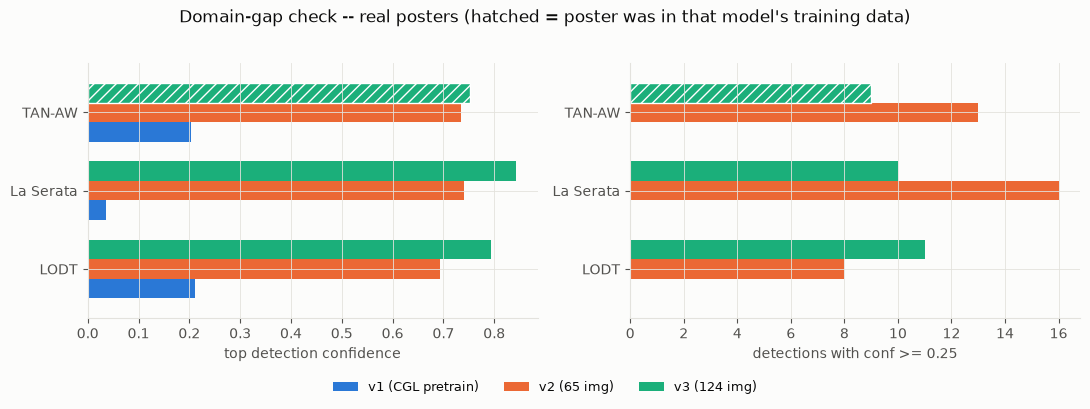

top_conf               usable_detections            
model           v1     v2     v3                v1    v2    v3
poster                                                        
LODT         0.211  0.694  0.793               0.0   8.0  11.0
La Serata    0.035  0.740  0.843               0.0  16.0  10.0
TAN-AW       0.204  0.735  0.753               0.0  13.0   9.0

In [5]:
with open(ROOT / "results/yolo_domain_gap_check.json") as f:
    gap = json.load(f)

gap_rows = []
for version, per_poster in gap["results"].items():
    for poster, m in per_poster.items():
        gap_rows.append({"poster": poster, "model": version,
                         "top_conf": m["top_conf"], "usable_detections": m["n_ge_025"]})
gap_df = pd.DataFrame(gap_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, label in [(axes[0], "top_conf", "top detection confidence"),
                          (axes[1], "usable_detections", "detections with conf >= 0.25")]:
    gap_df.pivot(index="poster", columns="model", values=metric)[["v1", "v2", "v3"]].plot(
        kind="barh", ax=ax, color=[SERIES_1, SERIES_2, SERIES_3], width=0.75)
    ax.set_xlabel(label)
    ax.set_ylabel("")
    ax.get_legend().remove()
    # Hatch any bar whose poster was in that checkpoint's training data.
    posters = list(gap_df.pivot(index="poster", columns="model", values=metric).index)
    for container, version in zip(ax.containers, ["v1", "v2", "v3"]):
        for bar, poster in zip(container, posters):
            if gap["seen_in_training"][version][poster]:
                bar.set_hatch("///")
                bar.set_edgecolor("white")
fig.legend(["v1 (CGL pretrain)", "v2 (65 img)", "v3 (124 img)"], loc="lower center",
           ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Domain-gap check -- real posters (hatched = poster was in that model's training data)", y=1.02)
fig.tight_layout()
save(plt.gcf(), "nb_yolo_domain_gap")
plt.show()

gap_df.pivot(index="poster", columns="model", values=["top_conf", "usable_detections"])

### v3 vs. v4 on the same cleaned validation labels (notes §3.25)

Why detection was weak on master layouts: partly the labels (60 boxes cover
more than half their poster; `embellishment` mixes sparkles with mascots),
mostly the model and its input size (YOLOv8n at 640 px, where a poster's
logo row is a few dozen pixels high). v4 is YOLOv8s from COCO weights at
1024 px, trained on the 124-image batch with the over-half boxes removed.
Both are scored on the same cleaned validation labels.

**Reading it:** logos and text improve most (logo mAP50 0.62 → 0.82, recall
0.55 → 0.76): the capacity and resolution fix. Embellishment doesn't move
(recall 0.17 → 0.18): a class-definition problem no model size fixes, which
is why the group re-annotated the batch (`notes/annotation_guidelines.md`). v4 changed size, resolution,
initialisation and labels together; v5 (below), trained with v4's exact
recipe on the group's re-annotation, isolates the labels' share.

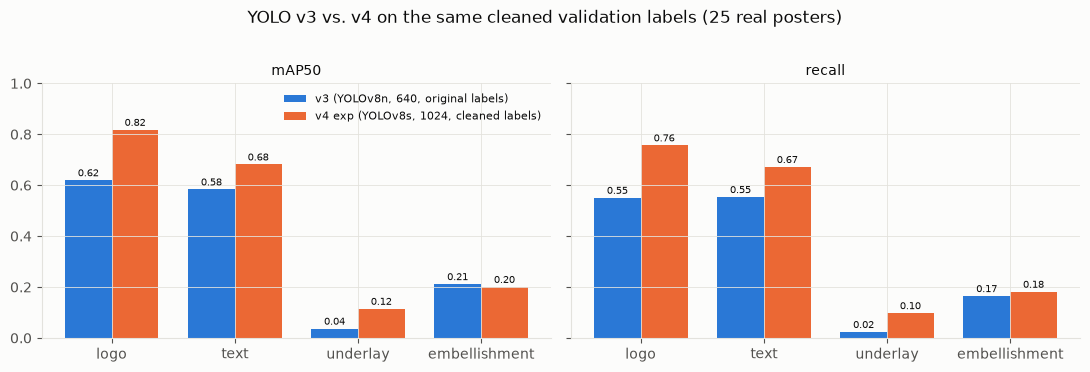

,mAP50,mAP50-95,precision,recall
v3,0.363,0.213,0.526,0.324
v4 exp,0.454,0.300,0.562,0.427


In [6]:
with open(ROOT / "results/yolo_v4_experiment.json") as f:
    yolo4 = json.load(f)
runs = {k: v for k, v in yolo4.items() if isinstance(v, dict)}
labels = {k: k.split(" (")[0] for k in runs}          # "v3", "v4 exp"
classes = list(next(iter(runs.values()))["per_class_mAP50"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
width = 0.38
for ax, metric, title in [(axes[0], "per_class_mAP50", "mAP50"), (axes[1], "per_class_recall", "recall")]:
    for j, (name, run) in enumerate(runs.items()):
        vals = [run[metric][c] for c in classes]
        xs = [k + (j - 0.5) * width for k in range(len(classes))]
        ax.bar(xs, vals, width=width, color=[SERIES_1, SERIES_2][j], label=name)
        for x, v in zip(xs, vals):
            ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=TEXT_PRIMARY)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("YOLO v3 vs. v4 on the same cleaned validation labels (25 real posters)", y=1.02)
plt.tight_layout()
save(plt.gcf(), "nb_yolo_v3_v4")
plt.show()

pd.DataFrame({labels[k]: {"mAP50": r["mAP50"], "mAP50-95": r["mAP50-95"], "precision": r["precision"],
                          "recall": r["recall"]} for k, r in runs.items()}).T

### v4 vs. v5: the group's 200-image re-annotation (notes §3.30)

v5 is v4's exact recipe (YOLOv8s from COCO, 1024 px, AMP, seed 0) trained on
the group's re-annotation of **200** master layouts (160 train / 40
validation). The export kept the 4 classes; its polygon rows were converted
to boxes first (`prepare_master_layout_dataset.py`). Both models are scored
on the new validation labels, each at its own image size and in its own
class order, leaving out every image either model trained on: 7 v4 trained
on, and HIRAYA, which sits in both of v5's splits. 32 images remain. 25 of
them were v4's own validation images, which picked its best checkpoint, so
if anything v4 is flattered.

**Reading it:** the re-annotation fixed what model size couldn't.
Embellishment recall goes 0.21 → 0.51 and underlay 0.10 → 0.52; logo
mAP50 reaches 0.98. Part of the gain is v5 having learned the new labelling
conventions the validation labels also follow, but logo and embellishment
improve on any reading. **v5 is the deployed detector.**

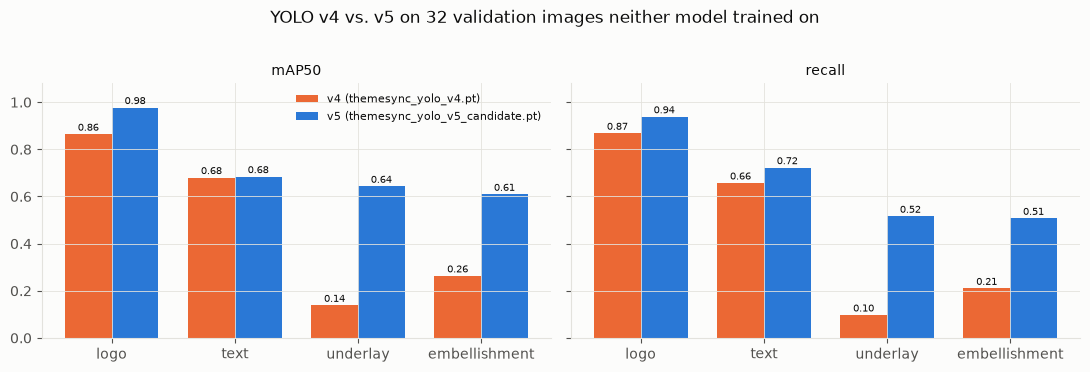

,mAP50,mAP50-95,precision,recall
v4,0.486,0.311,0.580,0.458
v5,0.728,0.496,0.841,0.671


In [7]:
with open(ROOT / "results/yolo_v5_comparison.json") as f:
    yolo5 = json.load(f)
classes = ["logo", "text", "underlay", "embellishment"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
width = 0.38
for ax, metric in [(axes[0], "mAP50"), (axes[1], "recall")]:
    for j, (name, m) in enumerate(yolo5["models"].items()):
        vals = [m["per_class"][c][metric] for c in classes]
        xs = [k + (j - 0.5) * width for k in range(len(classes))]
        ax.bar(xs, vals, width=width, color=[SERIES_2, SERIES_1][j], label=f"{name} ({m['checkpoint']})")
        for x, v in zip(xs, vals):
            ax.text(x, v + 0.015, f"{v:.2f}", ha="center", fontsize=7, color=TEXT_PRIMARY)
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_title(metric, fontsize=10)
    ax.set_ylim(0, 1.08)
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle(f"YOLO v4 vs. v5 on {yolo5['val_images']} validation images neither model trained on", y=1.02)
plt.tight_layout()
save(plt.gcf(), "nb_yolo_v4_v5")
plt.show()

pd.DataFrame({k: {"mAP50": m["mAP50"], "mAP50-95": m["mAP50-95"], "precision": m["precision"],
                  "recall": m["recall"]} for k, m in yolo5["models"].items()}).T

### Mean IoU of the deployed detector on the 40 validation images (Table 7; notes §3.41)

p.62's IoU: the deployed v5 detector at its own operating point (confidence ≥ 0.25,
or ≥ 0.15 for title-sized text) against the validation labels. In each image and
class, every ground-truth box is paired with at most one detection, maximising the
total IoU (Hungarian algorithm). The strict mean counts a missed box as 0; "found"
is IoU ≥ 0.5. `src/evaluation/yolo_iou.py` → `results/yolo_iou.json`.

In [8]:
with open(ROOT / "results/yolo_iou.json") as f:
    yolo_iou = json.load(f)
subset = next(iter(yolo_iou["results"]))
iou_table = pd.DataFrame(yolo_iou["results"][subset]).T[
    ["ground_truth_boxes", "strict_mean_iou", "strict_sd", "recall", "precision", "found_mean_iou", "found_sd"]]
print(f"{yolo_iou['weights']} at {yolo_iou['settings']['image_size']} px -- {subset}")
iou_table

themesync_yolo_v5.pt at 1024 px -- all 40 validation images


,ground_truth_boxes,strict_mean_iou,strict_sd,recall,precision,found_mean_iou,found_sd
logo,140.0,0.8439,0.1894,0.9571,0.9571,0.8816,0.0626
text,260.0,0.6791,0.3011,0.7962,0.6946,0.8183,0.1048
underlay,41.0,0.5485,0.4140,0.6341,0.6047,0.8504,0.0987
embellishment,166.0,0.4452,0.4002,0.5301,0.6331,0.8093,0.0981
all,607.0,0.6443,0.3508,0.7496,0.7339,0.8371,0.0970


## Phase 1 -- GNN: v1 as deployed, v2, and v3 (held-out CGL layouts)

v1 was trained with each CGL layout's *true* positions as input, but at
inference every node started at (0, 0). v2 starts training and inference
from the same naive stack and learns designers' real positions and spacing
(notes §3.22). **v3** (the default) is trained from two starts per layout:
the naive stack (no master) and the layout's own structure distorted the
way a cross-format mapping distorts it, which is what Stage 2 feeds it from
a real master layout (notes §3.26). Every row is scored on the same 2,900
held-out CGL layouts (a seeded 5% of CGL train; CGL's own test split has no
annotations), each model fed the input it receives in the pipeline. Lower
is better for both errors (fractions of the canvas).

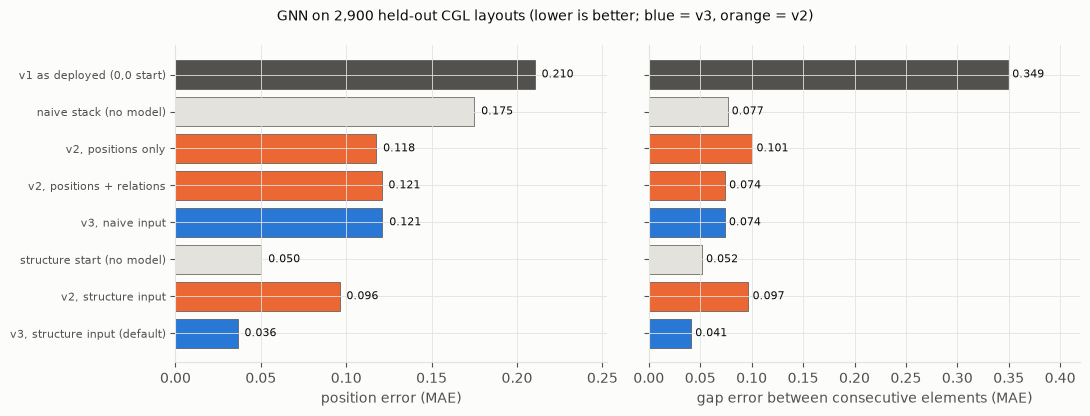

,mae_xy,mae_gap,order_kept,overlap
"v1 as deployed (0,0 start)",0.2104,0.3494,0.4717,0.0020
naive stack (no model),0.1750,0.0766,1.0000,0.0000
"v2, positions only",0.1176,0.1007,0.9981,0.0000
"v2, positions + relations",0.1207,0.0741,0.9986,0.0000
"v3, naive input",0.1212,0.0739,0.9991,0.0000
structure start (no model),0.0503,0.0517,0.9812,0.0044
"v2, structure input",0.0961,0.0969,0.9236,0.0037
"v3, structure input (default)",0.0364,0.0411,0.9708,0.0005


In [9]:
with open(ROOT / "results/gnn_heldout_eval.json") as f:
    gnn_eval = json.load(f)

gnn_df = pd.DataFrame(gnn_eval["results"]).T[["mae_xy", "mae_gap", "order_kept", "overlap"]]
def colour(name):
    if name.startswith("v1"):
        return TEXT_SECONDARY
    if "no model" in name:
        return GRID
    return SERIES_2 if name.startswith("v2") else SERIES_1
colors = [colour(n) for n in gnn_df.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, label in [(axes[0], "mae_xy", "position error (MAE)"),
                          (axes[1], "mae_gap", "gap error between consecutive elements (MAE)")]:
    vals = gnn_df[metric]
    ax.barh(range(len(vals)), vals, color=colors, edgecolor=TEXT_SECONDARY, linewidth=0.5)
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(vals.index if ax is axes[0] else [""] * len(vals), fontsize=8)
    ax.invert_yaxis()
    for i, v in enumerate(vals):
        ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=TEXT_PRIMARY)
    ax.set_xlabel(label)
    ax.set_xlim(0, vals.max() * 1.2)
fig.suptitle(f"GNN on {gnn_eval['heldout_layouts']:,} held-out CGL layouts (lower is better; "
             "blue = v3, orange = v2)", fontsize=10)
plt.tight_layout()
save(plt.gcf(), "nb_gnn_heldout")
plt.show()

gnn_df.round(4)

**Reading it:** v1 was worse than using no model at all. From the naive
stack, v2 and v3 are equally good (position error 0.121 vs. 0.175 for the
stack itself). From a master's structure, v3 cuts the structure start's
position error by 28% (0.036 vs. 0.050), its gap error by 20% and its
overlap by 89%; v2, never trained on such a start, makes it worse (0.096).

### What Stage 2 needs on a real master: keep the anchors, place the rest

On a real master the mapped anchors aren't noise: they are the composition
being transferred. So each held-out layout is anchored at its **real**
centres, with up to half its elements left unmapped (placed by
interpolation), and the error is split into anchored and unmapped
elements. Raw v3, trained only on distorted starts, still "corrects" the
anchors (2.6% of the height) and places the unmapped elements no better
than interpolation. Registered to the anchors
(`graph_builder.register_to_anchors`, what Stage 2 now does), it keeps them
exactly and places the unmapped elements 8% better than interpolation.
v2 registered is worse than interpolation: v3's structure training is what
earns the gain.

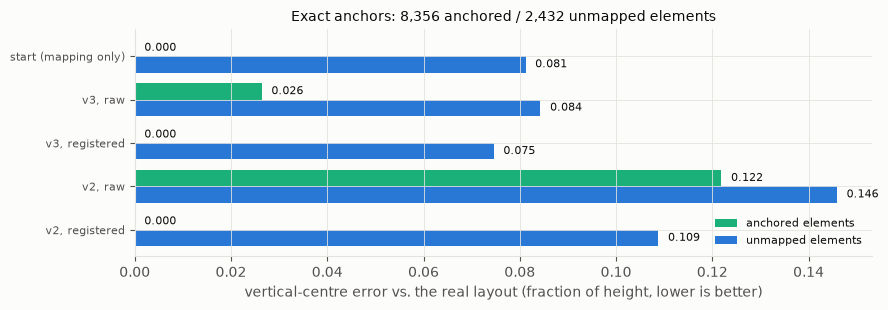

,anchored,unmapped,all
start (mapping only),0.0000,0.0812,0.0183
"v3, raw",0.0264,0.0843,0.0395
"v3, registered",0.0000,0.0746,0.0168
"v2, raw",0.1219,0.1459,0.1273
"v2, registered",0.0000,0.1088,0.0245


In [10]:
exact = pd.DataFrame(gnn_eval["exact_anchors"]["results"]).T[["anchored", "unmapped", "all"]]
fig, ax = plt.subplots(figsize=(9, 3.2))
width = 0.38
for j, (col, colr) in enumerate([("anchored", SERIES_3), ("unmapped", SERIES_1)]):
    ys = [k + (j - 0.5) * width for k in range(len(exact))]
    ax.barh(ys, exact[col], height=width, color=colr, label=f"{col} elements")
    for y, v in zip(ys, exact[col]):
        ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=8, color=TEXT_PRIMARY)
ax.set_yticks(range(len(exact)))
ax.set_yticklabels(exact.index, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("vertical-centre error vs. the real layout (fraction of height, lower is better)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"Exact anchors: {gnn_eval['exact_anchors']['anchored_elements']:,} anchored / "
             f"{gnn_eval['exact_anchors']['unmapped_elements']:,} unmapped elements", fontsize=10)
plt.tight_layout()
save(plt.gcf(), "nb_gnn_exact_anchors")
plt.show()

exact.round(4)

## Phase 2 -- Structural accuracy, stress test and latency (Objective 2)

Three checks of the reactive layout synthesis engine, all run on the Windows
workstation (RTX 3060; notes §3.42–3.44, §3.47):

* **The 64 rated layouts** (Table 11), read from the files the Phase 4 packets were
  printed from: F1 as p.56 defines it, the reading order, and whether every rendered
  line of text fits its box (measured with the bundled Montserrat's glyph metrics).
* **The stress test of the synthetic templates** (Table 12): every text field up to its
  maximum length and one character over, and 1–10 signature blocks.
* **The latency of 1,360 designer edits** in 34 sessions (Table 13).

In [11]:
with open(ROOT / "results/rated_layouts_check.json") as f:
    rated = json.load(f)
rated_table = pd.DataFrame({k: {"layouts": v["layouts"], "F1 = 1.0 on all": v["f1_all_1"],
                                "reading order kept": v["reading_order_kept"], "text fits its box": v["text_fits"],
                                "text over other content": len(v["text_over_text"]) + len(v["text_over_picture"]),
                                "smallest text (pt)": v["smallest_text_pt"]}
                            for k, v in rated["summary"].items()}).T
print(f"{rated['layouts']} rated layouts; all match the Phase 4 key: {rated['all_match_key']}")
rated_table

64 rated layouts; all match the Phase 4 key: True


,layouts,F1 = 1.0 on all,reading order kept,text fits its box,text over other content,smallest text (pt)
certificate gnn,16,True,16,16,0,7.8
certificate baseline,16,True,16,16,0,7.8
event_id gnn,16,True,16,14,0,6.5
event_id baseline,16,True,16,14,0,6.5


In [12]:
with open(ROOT / "results/stress_test.json") as f:
    stress = json.load(f)
rows = {}
for fmt, s in stress["summary"].items():
    rows[fmt] = {
        "runs (passed)": f"{s['runs']} ({s['passed']})",
        "every field at max, words": "fits" if s["first_failure_words"] is None else "fails",
        "breaking points": "; ".join(f"{b['field']} ({b['kind']}) from {b['shortest_failing']} of {b['max_characters']}"
                                     for b in s["breaking_points"]) or "none",
        "max + 1 rejected": s["over_max_all_rejected"],
        "signature blocks clean up to": s["signatures_largest_count_passing_from_1"],
        "smallest text (pt)": s["smallest_text_pt"],
    }
pd.DataFrame(rows).T

,runs (passed),"every field at max, words",breaking points,max + 1 rejected,signature blocks clean up to,smallest text (pt)
certificate,33 (19),fails,Issuing_Organization (words) from 64 of 150; I...,True,5,7.5
event_id,19 (11),fails,Event_Details (words) from 122 of 160; Event_D...,True,None,3.3


In [13]:
with open(ROOT / "results/latency_benchmark.json") as f:
    latency = json.load(f)
RESOLVE = ("on-drop", "on-resize-complete", "lock-toggle")
events = pd.DataFrame([e for r in latency["runs"] for e in r["events"]])
groups = {
    "solver (Cassowary re-solve)": events["solver_ms"].dropna(),
    "full edit, re-solving (move, resize, lock)": events.loc[events["type"].isin(RESOLVE), "full_ms"],
    "full edit, re-drawing only": events.loc[~events["type"].isin(RESOLVE), "full_ms"],
    "full edit, all": events["full_ms"],
}
pd.DataFrame({name: {"edits": len(v), "median ms": v.median(), "95th pct ms": v.quantile(0.95, interpolation="higher"),
                     "max ms": v.max(), "within 0.1 s": (v <= 100).mean(), "within 1.0 s": (v <= 1000).mean()}
              for name, v in groups.items()}).T.round(3)

,edits,median ms,95th pct ms,max ms,within 0.1 s,within 1.0 s
solver (Cassowary re-solve),1012.0,0.5,1.2,2.1,1.000,1.0
"full edit, re-solving (move, resize, lock)",1012.0,104.1,177.0,226.1,0.469,1.0
"full edit, re-drawing only",348.0,12.4,37.8,46.4,1.000,1.0
"full edit, all",1360.0,90.9,175.2,226.1,0.605,1.0


## Phase 3 -- Stage 2 conditions on real master layouts

Re-run 2026-10-06 on the current system (notes §3.25-3.31): YOLO v5, the
GNN v3 with its output registered to the master's anchors, six candidates
per run that differ in layout archetype (classic, left-aligned, art column,
banner, floating card, full-width band) as well as margin, rhythm and motif
arrangement, the active candidate being the fittest of the layout type the
master's composition calls for (§3.31), and seeded colour clustering (§3.29; earlier runs carried
palette noise). The battery runs the full pipeline (the same
`OrchestrationSession` the dashboard uses) on the **16 unseen Phase 4 event
posters** (the group's new set), for each format, under three Stage 2 conditions: **GNN-guided**
(the master's mapped structure, refined by the GNN), **mapping only** (the
mapped structure, no GNN: the ablation) and the **baseline** (no structure,
no GNN). 96 runs. Each master is one trial: the pipeline is deterministic
per input.

Besides the fitness terms, each run records its **structure error**: how
far the output's anchored elements (logo row and header on certificates;
also title and details on the event ID) sit vertically from their
counterparts on the master, as a fraction of the height. It is reported
for the winner and averaged over all six candidates, because certificate
candidates often tie on C_total and the winner then reflects the ranking's
tie-break more than Stage 2.

In [14]:
with open(ROOT / "results/experiment_log.json") as f:
    exp = json.load(f)

METHODS = [("GNN-guided", "gnn_trials"), ("Mapping only", "mapping_trials"), ("Baseline", "base_trials")]
rows = []
for domain, dd in exp["results"].items():
    for method, key in METHODS:
        for t in dd.get(key, []):
            rows.append({
                "format": dd["domain_label"], "method": method, "poster": t["poster"],
                "C_total": t["C_total"], "P_collision": t["P_collision"], "P_align": t["P_align"],
                "P_space": t["P_space"], "P_legibility": t["P_legibility"],
                "structure_error": t.get("structure_error"), "structure_error_all": t.get("structure_error_all"),
                "winner": t["winner"], "latency_ms": t["latency_total"],
            })
trials_df = pd.DataFrame(rows)
order = {m: k for k, (m, _) in enumerate(METHODS)}

penalties = (trials_df.groupby(["format", "method"])
             [["C_total", "P_collision", "P_align", "P_space", "P_legibility", "structure_error",
               "structure_error_all", "latency_ms"]]
             .agg(["mean", "std"]).round(4))
penalties = penalties.iloc[sorted(range(len(penalties)), key=lambda k: (penalties.index[k][0],
                                                                         order[penalties.index[k][1]]))]
penalties

C_total         P_collision       \
                                           mean     std        mean  std   
format                     method                                          
Academic Certificate (4:3) GNN-guided    0.0125  0.0250         0.0  0.0   
                           Mapping only  0.0125  0.0250         0.0  0.0   
                           Baseline      0.0126  0.0251         0.0  0.0   
Event ID (A6, 1:1.414)     GNN-guided    0.1633  0.0133         0.0  0.0   
                           Mapping only  0.1621  0.0128         0.0  0.0   
                           Baseline      0.1583  0.0135         0.0  0.0   

                                        P_align      P_space          \
                                           mean  std    mean     std   
format                     method                                      
Academic Certificate (4:3) GNN-guided       0.0  0.0  0.0108  0.0254   
                           Mapping only     0.0  0.0  0.0108  0.0254   
                           Baseline         0.0  0.0  0.0108  0.0254   
Event ID (A6, 1:1.414)     GNN-guided       0.0  0.0  0.1508  0.0140   
                           Mapping only     0.0  0.0  0.1508  0.0140   
                           Baseline         0.0  0.0  0.1508  0.0140   

                                        P_legibility         structure_error  \
                                                mean     std            mean   
format                     method                                              
Academic Certificate (4:3) GNN-guided         0.0011  0.0023          0.0545   
                           Mapping only       0.0011  0.0023          0.0545   
                           Baseline           0.0012  0.0025          0.0905   
Event ID (A6, 1:1.414)     GNN-guided         0.0083  0.0081          0.0495   
                           Mapping only       0.0075  0.0075          0.0495   
                           Baseline           0.0050  0.0054          0.1160   

                                                structure_error_all          \
                                            std                mean     std   
format                     method                                             
Academic Certificate (4:3) GNN-guided    0.0391              0.0564  0.0319   
                           Mapping only  0.0391              0.0564  0.0319   
                           Baseline      0.0364              0.0887  0.0357   
Event ID (A6, 1:1.414)     GNN-guided    0.0385              0.0451  0.0362   
                           Mapping only  0.0385              0.0451  0.0362   
                           Baseline      0.0460              0.1171  0.0460   

                                        latency_ms             
                                              mean        std  
format                     method                              
Academic Certificate (4:3) GNN-guided    5826.7387  2491.0246  
                           Mapping only  5719.1256  2501.2539  
                           Baseline      5772.4225  2553.8399  
Event ID (A6, 1:1.414)     GNN-guided    5215.5525  2399.6691  
                           Mapping only  5177.5019  2363.8448  
                           Baseline      5153.6056  2392.6120

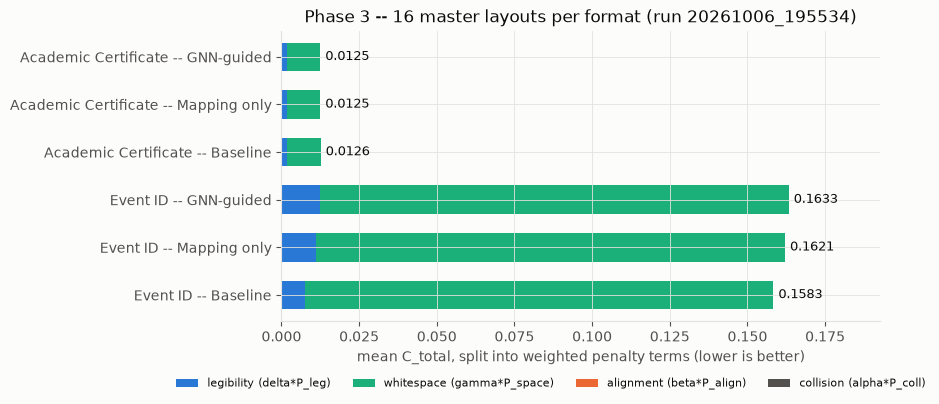

,legibility (delta*P_leg),whitespace (gamma*P_space),alignment (beta*P_align),collision (alpha*P_coll),C_total
Academic Certificate -- GNN-guided,0.0017,0.0108,0.0,0.0,0.0125
Academic Certificate -- Mapping only,0.0017,0.0108,0.0,0.0,0.0125
Academic Certificate -- Baseline,0.0018,0.0108,0.0,0.0,0.0126
Event ID -- GNN-guided,0.0124,0.1508,0.0,0.0,0.1633
Event ID -- Mapping only,0.0112,0.1508,0.0,0.0,0.1621
Event ID -- Baseline,0.0075,0.1508,0.0,0.0,0.1583


In [15]:
import sys
sys.path.insert(0, str(ROOT / "src" / "solvers"))
from optimization_engine import HeuristicEvaluator

# Split each mean C_total into its weighted Formula 3.11 terms, using the
# evaluator's own weights.
w = HeuristicEvaluator()
means = trials_df.groupby(["format", "method"])[["C_total", "P_collision", "P_align", "P_space", "P_legibility"]].mean()
means = means.iloc[sorted(range(len(means)), key=lambda k: (means.index[k][0], order[means.index[k][1]]))]
parts = pd.DataFrame({
    "legibility (delta*P_leg)": w.delta * means["P_legibility"],
    "whitespace (gamma*P_space)": w.gamma * means["P_space"],
    "alignment (beta*P_align)": w.beta * means["P_align"],
    "collision (alpha*P_coll)": w.alpha * means["P_collision"],
})
parts.index = [f"{fmt.split(' (')[0]} -- {method}" for fmt, method in parts.index]
fig, ax = plt.subplots(figsize=(9, 4.2))
parts.plot(kind="barh", stacked=True, ax=ax, color=[SERIES_1, SERIES_3, SERIES_2, TEXT_SECONDARY], width=0.6)
for i, total in enumerate(means["C_total"]):
    ax.text(total + means["C_total"].max() * 0.01, i, f"{total:.4f}", va="center", fontsize=9, color=TEXT_PRIMARY)
ax.invert_yaxis()
ax.set_xlabel("mean C_total, split into weighted penalty terms (lower is better)")
ax.set_ylabel("")
ax.set_xlim(0, means["C_total"].max() * 1.18)
ax.set_title(f"Phase 3 -- {exp['config']['masters']} master layouts per format (run {exp['run_id']})")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=4)
plt.tight_layout()
save(plt.gcf(), "nb_phase3_fitness_terms")
plt.show()

parts.assign(C_total=means["C_total"].values).round(4)

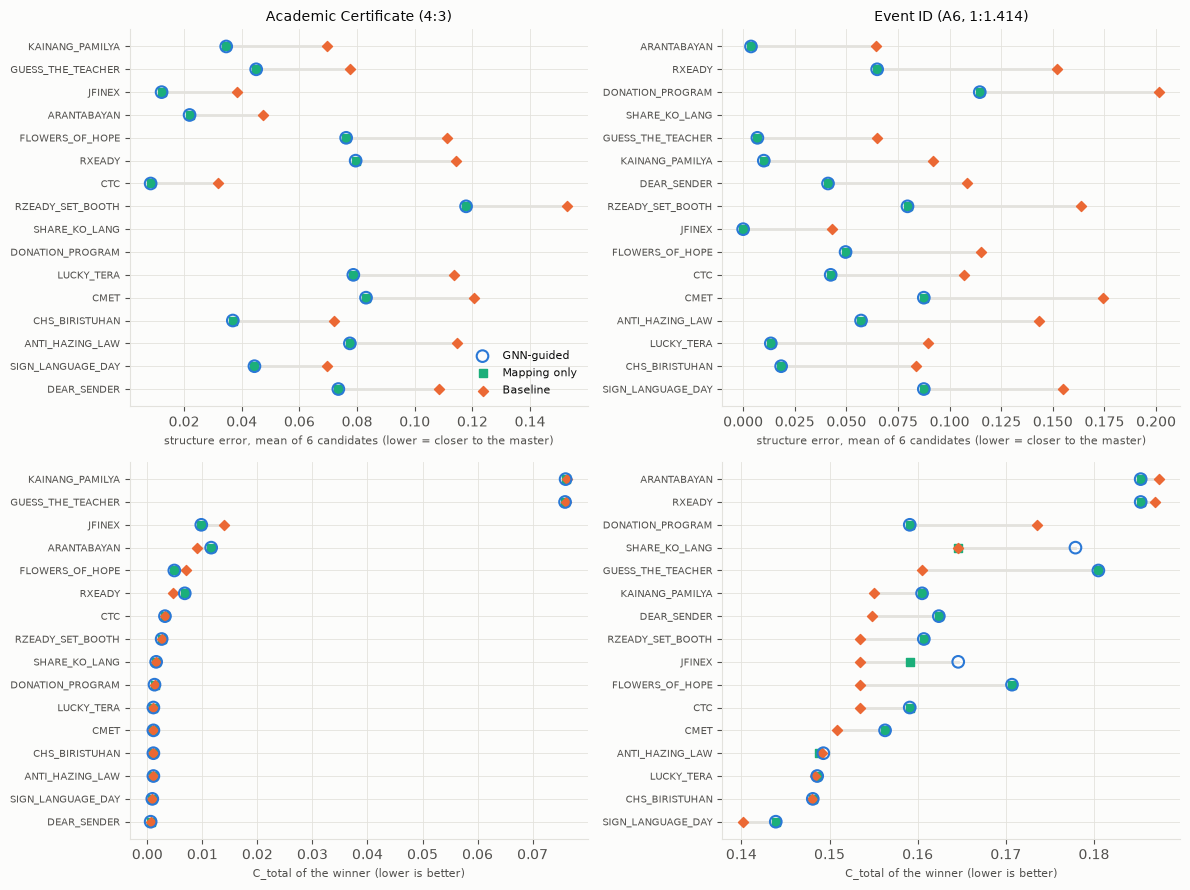

In [16]:
# Per master: structure error (all six candidates) and C_total, for each condition.
# GNN is drawn as a ring: it coincides with mapping on 29 of 30 runs.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
marks = {"GNN-guided": (SERIES_1, "o"), "Mapping only": (SERIES_3, "s"), "Baseline": (SERIES_2, "D")}
for col, (domain, dd) in enumerate(exp["results"].items()):
    trials = {m: {t["poster"]: t for t in dd.get(k, [])} for m, k in METHODS}
    posters = sorted(trials["Baseline"], key=lambda p: trials["Baseline"][p]["C_total"])
    for row, (metric, label) in enumerate([("structure_error_all", "structure error, mean of 6 candidates (lower = closer to the master)"),
                                            ("C_total", "C_total of the winner (lower is better)")]):
        ax = axes[row][col]
        for y, p in enumerate(posters):
            vals = [trials[m][p].get(metric) for m in marks if p in trials[m]]
            vals = [v for v in vals if v is not None]
            if vals:
                ax.plot([min(vals), max(vals)], [y, y], color=GRID, linewidth=2, zorder=1)
            for m, (c, mk) in marks.items():
                v = trials[m].get(p, {}).get(metric)
                if v is None:
                    continue
                if m == "GNN-guided":   # a ring on top, so it shows where it coincides with mapping
                    ax.scatter(v, y, facecolors="none", edgecolors=c, marker=mk, s=70, linewidths=1.5,
                               zorder=4, label=m if y == 0 else None)
                else:
                    ax.scatter(v, y, color=c, marker=mk, s=26, zorder=3, label=m if y == 0 else None)
        ax.set_yticks(range(len(posters)))
        ax.set_yticklabels([p.rsplit(".", 1)[0] for p in posters], fontsize=7)
        ax.set_xlabel(label, fontsize=8)
        if row == 0:
            ax.set_title(dd["domain_label"], fontsize=10)
axes[0][0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(plt.gcf(), "nb_phase3_structure_error")
plt.show()

**Reading this run (16 unseen master layouts per format, 96 runs, YOLO v5):**

- **Each poster now gets its own layout type** (notes §3.31): the active
  candidate is the fittest of the archetype the master's composition calls
  for. Certificates: classic 11, header banner 2, art column 2,
  left-aligned 1. Event IDs: classic 9, floating card 2, full-width band 2,
  left-aligned 3. Both conditions of a poster get the same type, so the
  GNN-vs-baseline comparison stays fair. (Before, Formula 3.11 alone chose
  classic for 14 of 16 certificates by exact ties, and left-aligned for all
  16 IDs.)
- **The master's structure reaches the output.** The GNN-guided output is
  closer to the master than the baseline on 15 of 16 event IDs (structure
  error 0.045 vs. 0.117) and on 14 of 16 certificates (0.056 vs. 0.089). The
  rest have no roles to map: SHARE KO LANG's script title isn't detected as
  a title, and on DONATION PROGRAM the organisation name beside the logos was
  merged into the title group, so nothing sits above the "title".
- **Formula 3.11 doesn't reward it.** Certificates mostly tie (equal on 10,
  GNN lower on 4, higher on 2). On event IDs the baseline scores slightly
  better (C_total 0.1583 vs. 0.1633; GNN higher on 13 of 16), through
  legibility: following a poster's composition puts text where the poster
  had its artwork. Means are higher than in earlier runs because the
  chosen layout type isn't always the lowest-scoring one (the art column
  and the card cost more under Formulas 3.14-3.15). Nothing in the fitness
  function measures "keeps the master's composition"; that is what Phase 4's
  MOS judges (visual hierarchy preservation, brand consistency).
- **GNN vs. mapping only:** the same anchors and layout types; the same
  fitness on 29 of 32 runs. The GNN moves the unmapped elements (name, role,
  the certificate's lower block) on 14 of 32 runs, by up to 7.5% of the
  height. Both formats are tall stacks with little vertical slack, so once
  the master's anchors are placed the solver's design rules leave little to
  decide. The GNN's gain over interpolation is shown on held-out data above,
  not in these scores.
- The 2026-09-29 run (YOLO v4, the earlier 15 posters, fitness-only choice)
  is kept as `results/experiment_log_20260929_old15_v4.json`.
- **Latency** is about 3-12 s per full run on the shared server; the GNN
  itself takes ~50 ms.

In [17]:
with open(ROOT / "results/evaluation_results.json") as f:
    ev = json.load(f)

fixed_rows = []
for method, trials in [("GNN-guided", ev["gnn_guided"]), ("Baseline", ev["baseline"])]:
    for t in trials:
        f1 = t["constraint_f1"]
        fixed_rows.append({
            "method": method,
            # GNN–solver overlap (renamed from "mean_iou" on 2026-10-09; not p.62's IoU)
            "gnn_solver_overlap": t.get("gnn_solver_overlap", t.get("mean_iou")),
            "C_total": t["heuristic_fitness"]["C_total"],
            "hard_nodes_kept": f"{f1['hard_preserved']}/{f1['total_hard']}",
            "f1_p56": f1["f1"],
            "collision_after_edits": f1.get("collision_after_edits"),
            "latency_ms": t["timings_ms"]["total_ms"],
        })
fixed_df = pd.DataFrame(fixed_rows).set_index("method")
print("Simulated designer events:", ev["gnn_guided"][0]["constraint_f1"].get("events"))
fixed_df

Simulated designer events: ['Moved {{Issuing_Organization}}', 'Resized {{Presentation_Line}}', 'Locked {{Certificate_ID}}']


,gnn_solver_overlap,C_total,hard_nodes_kept,f1_p56,collision_after_edits,latency_ms
method,,,,,,
GNN-guided,0.2559,1.1256,3/3,1.0,0.0,398.04
Baseline,NaN,1.1256,3/3,1.0,0.0,58.69


**Synthetic certificate (no master layout) plus simulated designer edits.**
With the synthetic theme there is no background to score legibility
against, so GNN and baseline tie on C_total (1.1256), consistent with the
battery above. The second part is the manuscript's "non-destructive
retention of manual user refinements" (p.54): three designer events are
simulated — a move (on-drop), a resize (on-resize-complete) and a lock — and
after the solver re-flows the other nodes, every Hard node must still sit
exactly where the designer left it (1 px tolerance). All three are kept, with
no overlap introduced, in both modes. `tests/test_certificate_pipeline.py`
checks the same property on every run (`test_hard_constraints_preserved`).

## Phase 3 -- Calibrating Formula 3.11's weights (notes §3.33, revision item 3.25)

p.43 and p.52 say the weights (α collision, β alignment, γ whitespace,
δ legibility) were calibrated in Phase 3. `src/evaluation/weight_calibration.py`
runs that calibration on the Phase 3 battery, i.e. the same 64 runs the
experts rate (16 posters × 2 formats × GNN/baseline). Its criteria were
fixed before the run:

- **A:** the chosen layout keeps the constraints (no overlap, nothing off
  the canvas), and α stays the highest weight.
- **B:** starting from the deployed weights, change one weight at a time
  (× 0.25, 0.5, 2, 4). Keep a change only if the chosen layouts get better
  on alignment, whitespace or legibility and worse on none.

It is an analysis only: the deployed weights stay as they are, because the
experts rated the layouts they chose.

In [18]:
with open(ROOT / "results/weight_calibration.json") as f:
    cal = json.load(f)
an = cal["analysis"]
s = an["sanity"]
print(f"Run {cal['timestamp']}: {s['runs']} runs; choices matching the Phase 4 packet: "
      f"{s['choice_matches_phase4_packet']}/{s['runs']}; candidates breaking the constraints: "
      f"{s['candidates_breaking_constraints']} of {s['runs'] * 6}")
print("Deployed weights:", an["deployed_weights"])

pd.DataFrame({
    rule: {
        "constraints kept": f"{a['at_deployed_weights']['constraints_kept']}/{a['at_deployed_weights']['constraints_possible']}",
        "criterion A": a["criterion_a"],
        "loop kept a change": bool(a["loop"]),
        "calibrated": a["calibrated"],
        "mean P_space of chosen": a["at_deployed_weights"]["P_space"],
        "mean P_legibility of chosen": a["at_deployed_weights"]["P_legibility"],
    }
    for rule, a in [("deployed choice (layout type, then fitness)", an["deployed"]),
                    ("plain ranking (lowest C_total of six)", an["plain"])]
}).T

Run 2026-10-08T17:37:25: 64 runs; choices matching the Phase 4 packet: 64/64; candidates breaking the constraints: 0 of 384
Deployed weights: {'alpha': 50.0, 'beta': 2.0, 'gamma': 1.0, 'delta': 1.5}


,constraints kept,criterion A,loop kept a change,calibrated,mean P_space of chosen,mean P_legibility of chosen
"deployed choice (layout type, then fitness)",64/64,True,False,True,0.08083,0.00389
plain ranking (lowest C_total of six),64/64,True,False,True,0.06988,0.00376


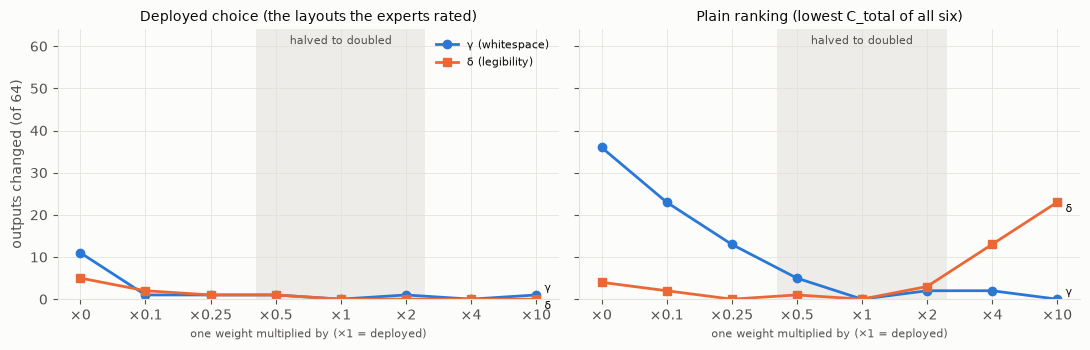

,×0,×0.1,×0.25,×0.5,×1,×2,×4,×10
deployed: alpha,0,0,0,0,0,0,0,0
deployed: beta,0,0,0,0,0,0,0,1
deployed: gamma,11,1,1,1,0,1,0,1
deployed: delta,5,2,1,1,0,0,0,0
plain: alpha,0,0,0,0,0,0,0,0
plain: beta,0,0,0,0,0,0,0,0
plain: gamma,36,23,13,5,0,2,2,0
plain: delta,4,2,0,1,0,3,13,23


In [19]:
# How many of the 64 rated outputs change when one weight is multiplied.
# alpha never changes one (no candidate ever overlaps) and beta changes at
# most 1 (only at x10), so the chart shows gamma and delta; the table has all four.
mults = [row["multiplier"] for row in an["deployed"]["sensitivity"]["gamma"]]
labels = ["×0" if m == 0 else f"×{m:g}" for m in mults]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (rule, title) in zip(axes, [("deployed", "Deployed choice (the layouts the experts rated)"),
                                    ("plain", "Plain ranking (lowest C_total of all six)")]):
    sens = an[rule]["sensitivity"]
    ax.axvspan(labels.index("×0.5") - 0.3, labels.index("×2") + 0.3, color=GRID, alpha=0.6, linewidth=0)
    ax.text(labels.index("×1"), 60.5, "halved to doubled", ha="center", fontsize=8, color=TEXT_SECONDARY)
    for key, name, color, marker, dy in [("gamma", "γ (whitespace)", SERIES_1, "o", 5),
                                         ("delta", "δ (legibility)", SERIES_2, "s", -5)]:
        ys = [row["outputs_changed"] for row in sens[key]]
        ax.plot(range(len(mults)), ys, color=color, linewidth=2, marker=marker, markersize=6, label=name)
        ax.annotate(name.split()[0], (len(mults) - 1, ys[-1]), xytext=(6, dy), textcoords="offset points",
                    va="center", fontsize=8, color=TEXT_PRIMARY)
    ax.set_xticks(range(len(mults)))
    ax.set_xticklabels(labels)
    ax.set_xlabel("one weight multiplied by (×1 = deployed)", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, 64)
axes[0].set_ylabel("outputs changed (of 64)")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
save(plt.gcf(), "nb_weight_sensitivity")
plt.show()

pd.DataFrame({f"{rule}: {k}": {lab: row["outputs_changed"] for lab, row in zip(labels, an[rule]["sensitivity"][k])}
              for rule in ("deployed", "plain") for k in ("alpha", "beta", "gamma", "delta")}).T

**Reading it:**

- **The deployed weights pass.** Criterion A holds and the loop kept no
  change, for the deployed choice and for the plain ranking. The analysis
  reproduces all 64 Phase 4 choices.
- **The rated layouts don't hinge on the exact values.** Halving or
  doubling any one weight changes at most 1 of the 64 rated layouts
  (KAINANG_PAMILYA's GNN certificate). Only dropping a term entirely
  (× 0) changes more: whitespace 11, legibility 5.
- **Why the weights matter so little here:**
  - Cassowary already prevents overlap, so no candidate has a collision
    and α never decides.
  - Every candidate is aligned (P_align ≤ 5 × 10⁻⁷), so β never decides.
  - The choices come down to whitespace against legibility, often by a
    hair. Of the 48 runs with two candidates of the chosen layout type, 22
    tie exactly.
- **Order, stated honestly:** the weights were set by p.43's priority rule
  (α highest) and confirmed by this calibration on 2026-10-08. That was
  after the Phase 4 layouts were generated and before any rating was
  analysed.

### A master-derived R_target (notes §3.46; analysis only)

Formula 3.14's whitespace target is fixed at 0.65. Replacing it with each master
poster's own whitespace ratio (Formula 3.14 applied to the master's detected logos
and text) and re-ranking the 64 rated runs' candidates shows how many outputs it
would have changed. `src/evaluation/r_target_analysis.py`.

In [20]:
with open(ROOT / "results/r_target_analysis.json") as f:
    rtarget = json.load(f)["analysis"]
print("sanity:", rtarget["sanity"])
pd.DataFrame({rule: {"master R (sum)": rtarget[rule]["master_sum"]["outputs_changed"],
                     "master R (union)": rtarget[rule]["master_union"]["outputs_changed"],
                     **{f"fixed R = {s['r_target']:.2f}": s["outputs_changed"] for s in rtarget[rule]["sweep"]}}
              for rule in ("deployed", "plain")})

sanity: {'runs': 64, 'ratios_reproduce_P_space': 64, 'choice_at_0.65_matches_pipeline': 64, 'choice_at_0.65_matches_phase4_key': 64}


,deployed,plain
master R (sum),2,20
master R (union),2,12
fixed R = 0.30,15,64
fixed R = 0.35,15,64
fixed R = 0.40,15,64
fixed R = 0.45,15,64
fixed R = 0.50,0,64
fixed R = 0.55,0,32
fixed R = 0.60,0,32
fixed R = 0.65,0,0


## Phase 4 -- Expert Aesthetic Validation (MOS; notes §3.48–3.49)

Four experts rated the 64 layouts (16 posters × 2 formats × structure mapping + GNN
and baseline) on Table 2's three parameters: 768 ratings, imported with
`mos_collector.py` into `results/mos_results.json`. The analysis is the plan adopted
from the consultation guide, committed (`b9a60ab`) before the scores were imported
and run unchanged: `src/evaluation/phase4_analysis.py` → `results/phase4_analysis.json`.
The exploratory analyses added afterwards are in `src/evaluation/phase4_posthoc.py`
→ `results/phase4_posthoc.json`; their p-values are uncorrected.

The baseline uses neither the structure mapping nor the GNN, so the comparison is
**structure mapping + GNN** against **baseline (neither)**.

In [21]:
with open(ROOT / "results/phase4_analysis.json") as f:
    p4 = json.load(f)
with open(ROOT / "results/phase4_posthoc.json") as f:
    p4post = json.load(f)
PARAM = {"overall": "Overall", "visual_hierarchy_preservation": "Visual Hierarchy Preservation",
         "brand_typographic_consistency": "Brand and Typographic Consistency",
         "constraint_whitespace_harmony": "Constraint and Whitespace Harmony"}
COND = {"gnn": "Mapping + GNN", "baseline": "Baseline"}
print(p4["design"])

def ms(c):
    return f"{c['mean']:.2f} ± {c['sd']:.2f}"

# Table 16 (MOS by parameter and condition) and Table 17 (by format)
t16 = pd.DataFrame({COND[c]: {PARAM[m]: ms(p4["q1_describe"][c][m]) for m in PARAM} for c in COND})
t16["All layouts"] = [ms(p4["q1_describe"]["all"][m]) for m in PARAM]
t17 = pd.DataFrame({f"{fmt} -- {COND[c]}": {PARAM[m]: ms(p4["q1_describe"][f"{fmt} {c}"][m]) for m in PARAM}
                    for fmt in ("certificate", "event_id") for c in COND}).T
display(t16)
t17

{'experts': ['Eisen Rose D. Galvante', 'Kyz Denise Aquino', 'Mark Joseph Orias', 'Mark Kenneth C. Ellorde'], 'layouts': 64, 'ratings': 768, 'pairs': 32, 'identical_pairs': ['LUCKY_TERA.jpg certificate']}


,Mapping + GNN,Baseline,All layouts
Overall,3.33 ± 0.89,3.73 ± 0.93,3.53 ± 0.93
Visual Hierarchy Preservation,3.61 ± 1.06,3.73 ± 1.11,3.67 ± 1.08
Brand and Typographic Consistency,3.47 ± 1.09,3.70 ± 1.02,3.59 ± 1.06
Constraint and Whitespace Harmony,2.92 ± 1.18,3.77 ± 1.13,3.35 ± 1.23


,Overall,Visual Hierarchy Preservation,Brand and Typographic Consistency,Constraint and Whitespace Harmony
certificate -- Mapping + GNN,3.50 ± 0.89,3.88 ± 1.05,3.56 ± 1.02,3.06 ± 1.28
certificate -- Baseline,3.78 ± 0.98,3.73 ± 1.20,3.78 ± 1.00,3.81 ± 1.19
event_id -- Mapping + GNN,3.17 ± 0.85,3.34 ± 1.01,3.38 ± 1.15,2.78 ± 1.06
event_id -- Baseline,3.69 ± 0.87,3.72 ± 1.02,3.62 ± 1.05,3.73 ± 1.07


In [22]:
# Table 18 (ratings given, all three parameters) and Table 19 (Kendall's W)
t18 = pd.DataFrame({COND[c]: p4["q1_rating_counts"][c]["all three"] for c in COND}).T
t19 = pd.DataFrame({PARAM[m]: {"W": w["W"], "chi2 (df 63)": w["chi2"], "p": w["p"]}
                    for m, w in p4["q2_kendall_w"].items()}).T
display(t18)
t19

,1,2,3,4,5
Mapping + GNN,23,69,120,101,71
Baseline,14,32,110,114,114


,W,chi2 (df 63),p
Overall,0.6296,158.655,3.303002e-10
Visual Hierarchy Preservation,0.5791,145.934,1.573714e-08
Brand and Typographic Consistency,0.4770,120.216,1.903356e-05
Constraint and Whitespace Harmony,0.5696,143.544,3.176921e-08


In [23]:
# Table 20: Wilcoxon signed-rank on the 32 pairs (two-sided, Holm over the four tests)
t20 = pd.DataFrame({PARAM[m]: {"baseline higher": r["lower"], "mapping + GNN higher": r["higher"], "equal": r["equal"],
                               "median diff": r["median_diff"], "T": r["statistic"], "p": r["p"],
                               "p (Holm)": r["p_holm"], "r": r["r"]}
                    for m, r in p4["q3_q9_wilcoxon"].items()}).T
sens = p4["sensitivity"]
sens_table = pd.DataFrame({PARAM[m]: {"paired t": sens["paired_t"][m]["t"], "p (t)": sens["paired_t"][m]["p"],
                                      "p Holm, without the identical pair": sens["wilcoxon_without_identical_pair"][m]["p_holm"],
                                      "p Holm, without ANTI_HAZING_LAW (post hoc)": p4post["main_tests_without_anti_hazing_law"][m]["p_holm"],
                                      "ICC(2,1)": sens["agreement_icc_krippendorff"][m]["ICC(2,1)"],
                                      "Krippendorff alpha": sens["agreement_icc_krippendorff"][m]["krippendorff_alpha"]}
                           for m in PARAM}).T
display(t20)
sens_table

,baseline higher,mapping + GNN higher,equal,median diff,T,p,p (Holm),r
Overall,25.0,2.0,5.0,-0.4167,9.5,0.000015,0.000046,-0.9497
Visual Hierarchy Preservation,16.0,7.0,9.0,-0.1250,88.5,0.127040,0.127040,-0.3587
Brand and Typographic Consistency,22.0,5.0,5.0,-0.2500,50.0,0.000485,0.000970,-0.7354
Constraint and Whitespace Harmony,26.0,2.0,4.0,-1.0000,4.0,0.000005,0.000022,-0.9803


,paired t,p (t),"p Holm, without the identical pair","p Holm, without ANTI_HAZING_LAW (post hoc)","ICC(2,1)",Krippendorff alpha
Overall,-6.5662,2.477082e-07,0.000050,0.000068,0.3061,0.2302
Visual Hierarchy Preservation,-1.4342,1.615278e-01,0.046143,0.152806,0.2604,0.2078
Brand and Typographic Consistency,-4.0997,2.767036e-04,0.001403,0.001403,0.1579,0.0099
Constraint and Whitespace Harmony,-8.3846,1.800912e-09,0.000032,0.000032,0.2688,0.2002


In [24]:
# Exploratory (post hoc): each expert, and the spacing of the rated layouts (Table 21)
experts = pd.DataFrame(p4post["per_expert_overall"]).T
spacing = pd.DataFrame({k: {"mapping + GNN": f"{v['gnn']['mean']:.3f} ± {v['gnn']['sd']:.3f}",
                            "baseline": f"{v['baseline']['mean']:.3f} ± {v['baseline']['sd']:.3f}",
                            "rho with the change in overall MOS": p4post["spearman_with_mos_difference"][f"d_{k} vs d_mos_overall"]["rho"],
                            "p (uncorrected)": p4post["spearman_with_mos_difference"][f"d_{k} vs d_mos_overall"]["p"]}
                        for k, v in p4post["layout_spacing"].items()}).T
display(experts)
spacing

,gnn_mean,baseline_mean,all_mean,pairs_gnn_higher,pairs_gnn_lower,pairs_equal
Eisen Rose D. Galvante,3.219,3.365,3.292,7.0,14.0,11.0
Kyz Denise Aquino,3.271,4.021,3.646,4.0,25.0,3.0
Mark Joseph Orias,2.708,3.052,2.880,7.0,20.0,5.0
Mark Kenneth C. Ellorde,4.135,4.500,4.318,6.0,16.0,10.0


,mapping + GNN,baseline,rho with the change in overall MOS,p (uncorrected)
largest_gap,0.072 ± 0.057,0.020 ± 0.003,-0.4195,0.016854
gap_cv,0.468 ± 0.435,0.000 ± 0.000,-0.4194,0.016875
spread,0.816 ± 0.054,0.746 ± 0.025,-0.4484,0.01006


## Figures for Chapter 4 (`results/figures/fig4_*.png` and `.pdf`)

Clean versions for the manuscript: no titles (the captions go in the LaTeX), sized
for a 6.5-inch text block, PNG at 300 dpi plus a vector PDF. Colours follow the
validated palette (blue = structure mapping + GNN, orange = baseline), with a second
cue (marker shape or hatching) so they also read in greyscale.

| File | What it shows | Suggested place |
|---|---|---|
| `fig4_structure_error` | structure error per poster, mapping + GNN vs baseline | Objective 1, beside Table 10 |
| `fig4_latency` | cumulative share of edits by time, with the 0.1 s and 1.0 s limits | Objective 2, beside Table 13 |
| `fig4_mos_by_parameter` | MOS ± SD by parameter and condition | Objective 3, beside Table 16 |
| `fig4_rating_distribution` | how often each rating 1–5 was given, per parameter and condition | Objective 3, beside Table 18 |
| `fig4_pairs` | each pair's overall MOS, baseline against mapping + GNN | Objective 3, beside Table 20 |
| `fig4_spacing_vs_mos` | change in largest gap against change in MOS (exploratory) | Objective 3, beside Table 21 |
| `fig4_example_pair` | the master, mapping + GNN and baseline for RXEADY's event ID | Objective 3 discussion |

In [25]:
FIG_W = 6.5                                    # inches: the manuscript's text block
INK, INK2, MUTED, HAIR = TEXT_PRIMARY, TEXT_SECONDARY, "#898781", "#e1e0d9"
C_GNN, C_BASE = SERIES_1, SERIES_2
FIG4_STYLE = {"figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7",
              "axes.grid": False, "font.size": 9, "axes.labelsize": 9, "xtick.labelsize": 8,
              "ytick.labelsize": 8, "legend.fontsize": 8}

ACRONYMS = {"Ctc": "CTC", "Cmet": "CMET", "Chs": "CHS", "Jfinex": "JFINEX", "Ssc": "SSC", "Rxeady": "RxEADY",
            "Rzeady": "RZEADY"}

def poster_label(name):
    words = name.rsplit(".", 1)[0].replace("_", " ").title().split()
    return " ".join(ACRONYMS.get(w, w) for w in words)

def legend_top(ax, handles, ncol=2):
    ax.legend(handles=handles, frameon=False, ncol=ncol, loc="lower left", bbox_to_anchor=(0, 1.01),
              handlelength=1.4, columnspacing=1.6, borderaxespad=0)

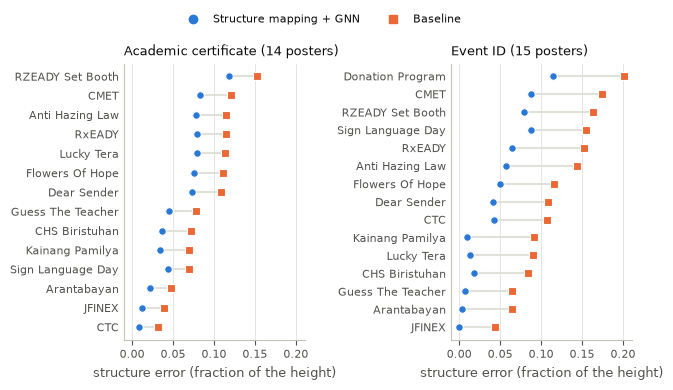

In [26]:
# fig4_structure_error: structure error per poster (mean of six candidates), Table 10's data
from matplotlib.lines import Line2D
with plt.rc_context(FIG4_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 3.9), sharex=True)
    for ax, (key, title) in zip(axes, (("certificate", "Academic certificate"), ("id", "Event ID"))):
        res = exp["results"][key]
        rows = [(t["poster"], t["structure_error_all"], b["structure_error_all"])
                for t, b in zip(res["gnn_trials"], res["base_trials"]) if t["structure_error_all"] is not None]
        rows.sort(key=lambda r: r[2])
        y = range(len(rows))
        for k, (p, g, b) in enumerate(rows):
            ax.plot([g, b], [k, k], color=HAIR, linewidth=1.5, zorder=1)
        ax.scatter([r[2] for r in rows], y, s=26, color=C_BASE, marker="s", edgecolor="white", linewidth=0.8, zorder=3)
        ax.scatter([r[1] for r in rows], y, s=30, color=C_GNN, marker="o", edgecolor="white", linewidth=0.8, zorder=3)
        ax.set_yticks(list(y), [poster_label(r[0]) for r in rows])
        ax.set_title(f"{title} ({len(rows)} posters)", fontsize=9, color=INK, loc="left")
        ax.grid(axis="x", color=HAIR, linewidth=0.6)
        ax.set_xlabel("structure error (fraction of the height)")
        ax.tick_params(axis="y", length=0)
    fig.legend(handles=[Line2D([], [], marker="o", color=C_GNN, linestyle="", label="Structure mapping + GNN"),
                        Line2D([], [], marker="s", color=C_BASE, linestyle="", label="Baseline")],
               frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(w_pad=2.5, rect=(0, 0, 1, 0.93))
    save(fig, "fig4_structure_error")
    plt.show()

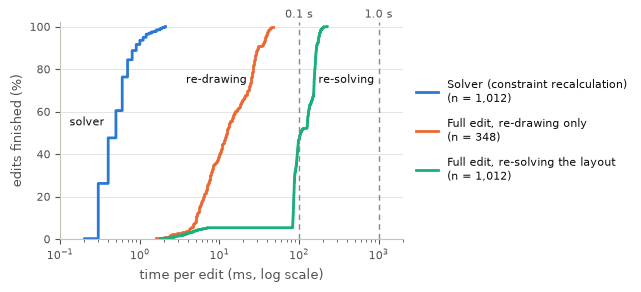

In [27]:
# fig4_latency: cumulative share of edits by time, with Nielsen's limits
import numpy as np
with plt.rc_context(FIG4_STYLE):
    fig, ax = plt.subplots(figsize=(FIG_W, 3.0))
    series = [("Solver (constraint recalculation)", groups["solver (Cassowary re-solve)"], SERIES_1),
              ("Full edit, re-drawing only", groups["full edit, re-drawing only"], SERIES_2),
              ("Full edit, re-solving the layout", groups["full edit, re-solving (move, resize, lock)"], SERIES_3)]
    handles = []
    for label, v, color in series:
        x = np.sort(v.to_numpy())
        y = np.arange(1, len(x) + 1) / len(x) * 100
        handles += ax.step(x, y, where="post", color=color, linewidth=2, label=f"{label}\n(n = {len(x):,})")
    # short direct labels beside each curve, clear of the others
    for text, xy, ha in (("solver", (0.36, 55), "right"), ("re-drawing", (22, 75), "right"),
                         ("re-solving", (175, 75), "left")):
        ax.text(*xy, text, fontsize=8, color=INK, ha=ha, va="center")
    for limit, text in ((100, "0.1 s"), (1000, "1.0 s")):
        ax.axvline(limit, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
        ax.text(limit, 103, text, fontsize=8, color=INK2, ha="center", va="bottom")
    ax.legend(handles=handles, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8,
              labelspacing=1.0)
    ax.set_xscale("log")
    ax.set_xlim(0.1, 2000)
    ax.set_ylim(0, 102)
    ax.set_xlabel("time per edit (ms, log scale)")
    ax.set_ylabel("edits finished (%)")
    ax.grid(axis="y", color=HAIR, linewidth=0.6)
    fig.tight_layout()
    save(fig, "fig4_latency")
    plt.show()

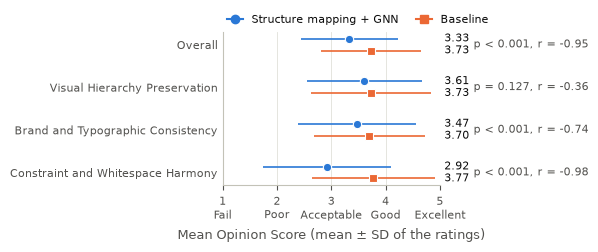

In [28]:
# fig4_mos_by_parameter: MOS ± SD by parameter and condition (Table 16)
with plt.rc_context(FIG4_STYLE):
    fig, ax = plt.subplots(figsize=(FIG_W, 2.6))
    order = list(PARAM)
    for k, m in enumerate(order):
        for dy, c, color, marker in ((-0.14, "gnn", C_GNN, "o"), (0.14, "baseline", C_BASE, "s")):
            d = p4["q1_describe"][c][m]
            ax.errorbar(d["mean"], k + dy, xerr=d["sd"], fmt=marker, color=color, ecolor=color, elinewidth=1.2,
                        capsize=0, markersize=6, markeredgecolor="white", markeredgewidth=0.8, alpha=1)
            ax.text(5.08, k + dy, f"{d['mean']:.2f}", va="center", fontsize=8, color=INK)
        r = p4["q3_q9_wilcoxon"][m]
        sig = "p < 0.001" if r["p_holm"] < 0.001 else f"p = {r['p_holm']:.3f}"
        ax.text(5.62, k, f"{sig}, r = {r['r']:+.2f}", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(order)), [PARAM[m] for m in order])
    ax.invert_yaxis()
    ax.set_xlim(1, 5)
    ax.set_xticks([1, 2, 3, 4, 5], ["1\nFail", "2\nPoor", "3\nAcceptable", "4\nGood", "5\nExcellent"])
    ax.grid(axis="x", color=HAIR, linewidth=0.6)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Mean Opinion Score (mean ± SD of the ratings)")
    legend_top(ax, [Line2D([], [], marker="o", color=C_GNN, label="Structure mapping + GNN"),
                    Line2D([], [], marker="s", color=C_BASE, label="Baseline")])
    fig.tight_layout()
    save(fig, "fig4_mos_by_parameter")
    plt.show()

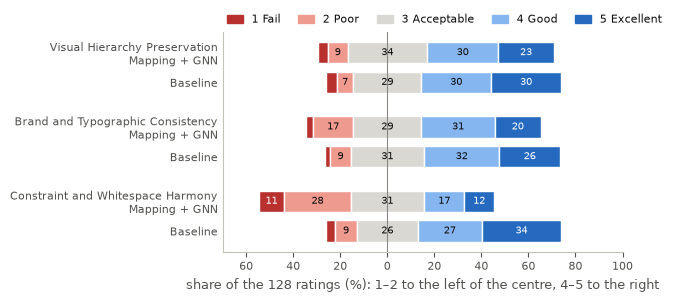

In [29]:
# fig4_rating_distribution: diverging bars of the ratings 1-5 (Table 18, per parameter)
from matplotlib.patches import Patch
RATING_COLORS = {1: "#b8312f", 2: "#ef9a8f", 3: "#d9d8d2", 4: "#86b6ef", 5: "#256abf"}
RATING_NAMES = {1: "1 Fail", 2: "2 Poor", 3: "3 Acceptable", 4: "4 Good", 5: "5 Excellent"}
with plt.rc_context(FIG4_STYLE):
    fig, ax = plt.subplots(figsize=(FIG_W, 3.1))
    labels, k = [], 0
    for m in list(PARAM)[1:]:
        for c in ("gnn", "baseline"):
            counts = p4["q1_rating_counts"][c][m]
            n = sum(counts.values())
            share = {v: counts[str(v)] / n * 100 for v in range(1, 6)}
            left = -(share[1] + share[2] + share[3] / 2)
            for v in range(1, 6):
                ax.barh(k, share[v], left=left, color=RATING_COLORS[v], edgecolor="white", linewidth=1, height=0.72)
                if share[v] >= 7:
                    ax.text(left + share[v] / 2, k, f"{share[v]:.0f}", ha="center", va="center", fontsize=7,
                            color="white" if v in (1, 5) else INK)
                left += share[v]
            labels.append(f"{PARAM[m]}\n{COND[c]}" if c == "gnn" else COND[c])
            k += 1
        k += 0.5
    ys = [0, 1, 2.5, 3.5, 5, 6]
    ax.set_yticks(ys, labels)
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlim(-70, 100)
    ax.set_xticks(range(-60, 101, 20), [f"{abs(t)}" for t in range(-60, 101, 20)])
    ax.set_xlabel("share of the 128 ratings (%): 1–2 to the left of the centre, 4–5 to the right")
    ax.tick_params(axis="y", length=0)
    legend_top(ax, [Patch(color=RATING_COLORS[v], label=RATING_NAMES[v]) for v in range(1, 6)], ncol=5)
    fig.tight_layout()
    save(fig, "fig4_rating_distribution")
    plt.show()

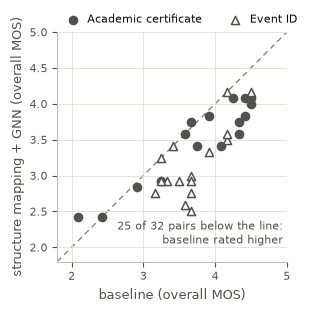

In [30]:
# fig4_pairs: each pair's overall MOS, baseline (x) against structure mapping + GNN (y)
pairs = pd.DataFrame(p4["pairs"])
with plt.rc_context(FIG4_STYLE):
    fig, ax = plt.subplots(figsize=(3.2, 3.2))
    ax.plot([1.8, 5], [1.8, 5], color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
    for fmt, marker, face in (("certificate", "o", INK2), ("event_id", "^", "white")):
        d = pairs[pairs["format"] == fmt]
        ax.scatter(d["overall_baseline"], d["overall_gnn"], s=34, marker=marker, facecolor=face, edgecolor=INK2,
                   linewidth=1.1, zorder=3, label="Academic certificate" if fmt == "certificate" else "Event ID")
    below = int((pairs["overall_gnn"] < pairs["overall_baseline"]).sum())
    ax.text(4.95, 2.0, f"{below} of {len(pairs)} pairs below the line:\nbaseline rated higher", ha="right",
            va="bottom", fontsize=8, color=INK2)
    ax.set_xlim(1.8, 5)
    ax.set_ylim(1.8, 5)
    ax.set_aspect("equal")
    ax.set_xlabel("baseline (overall MOS)")
    ax.set_ylabel("structure mapping + GNN (overall MOS)")
    ax.grid(color=HAIR, linewidth=0.6)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, handletextpad=0.3,
              borderaxespad=0)
    fig.tight_layout()
    save(fig, "fig4_pairs")
    plt.show()

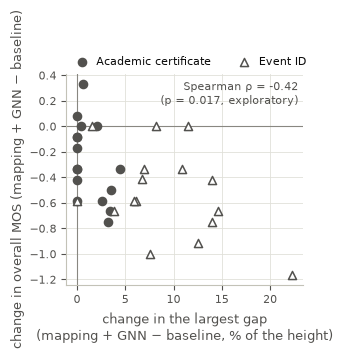

In [31]:
# fig4_spacing_vs_mos: change in largest gap against change in overall MOS (exploratory, Table 21)
sp = pd.DataFrame(p4post["pairs"])
rho = p4post["spearman_with_mos_difference"]["d_largest_gap vs d_mos_overall"]
with plt.rc_context(FIG4_STYLE):
    fig, ax = plt.subplots(figsize=(3.2, 3.2))
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    for fmt, marker, face in (("certificate", "o", INK2), ("event_id", "^", "white")):
        d = sp[sp["format"] == fmt]
        ax.scatter(d["d_largest_gap"] * 100, d["d_mos_overall"], s=34, marker=marker, facecolor=face,
                   edgecolor=INK2, linewidth=1.1, zorder=3, label="Academic certificate" if fmt == "certificate" else "Event ID")
    ax.text(0.98, 0.97, f"Spearman ρ = {rho['rho']:.2f}\n(p = {rho['p']:.3f}, exploratory)", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color=INK2)
    ax.set_xlabel("change in the largest gap\n(mapping + GNN − baseline, % of the height)")
    ax.set_ylabel("change in overall MOS (mapping + GNN − baseline)")
    ax.grid(color=HAIR, linewidth=0.6)
    ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, handletextpad=0.3,
              borderaxespad=0)
    fig.tight_layout()
    save(fig, "fig4_spacing_vs_mos")
    plt.show()

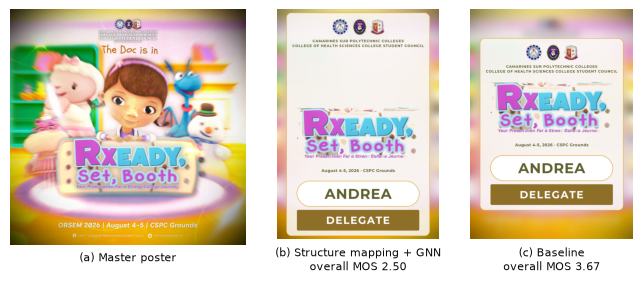

In [32]:
# fig4_example_pair: RXEADY's event ID -- the master, structure mapping + GNN, baseline
from PIL import Image
sample = ROOT / "data/phase4/samples/RXEADY"
panels = [(ROOT / "data/raw/phase4_posters/RXEADY.jpg", "(a) Master poster"),
          (sample / "event_id_gnn/ThemeSync_identification-card_populated.png", "(b) Structure mapping + GNN"),
          (sample / "event_id_baseline/ThemeSync_identification-card_populated.png", "(c) Baseline")]
row = pairs[(pairs["poster"] == "RXEADY.jpg") & (pairs["format"] == "event_id")].iloc[0]
mos = {1: row["overall_gnn"], 2: row["overall_baseline"]}
with plt.rc_context(FIG4_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 3.3), gridspec_kw={"width_ratios": [1.45, 1, 1]})
    for k, (ax, (path, label)) in enumerate(zip(axes, panels)):
        with Image.open(path) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_axis_off()
        ax.set_anchor("N")
        ax.text(0.5, -0.03, label + (f"\noverall MOS {mos[k]:.2f}" if k in mos else ""), transform=ax.transAxes,
                ha="center", va="top", fontsize=8, color=INK)
    fig.tight_layout(w_pad=1.0)
    save(fig, "fig4_example_pair")
    plt.show()